In [17]:
import yaml
import osmnx as ox
import pandas as pd
import geopandas as gpd
from pathlib import Path

ox.settings.requests_timeout = 300

PROCESSED = Path("../data/processed")
RAW_OSM = Path("../data/raw/osm")
RAW_OSM.mkdir(parents=True, exist_ok=True)

barrios = gpd.read_parquet(PROCESSED / "barrios_precios.parquet")
madrid_4326 = barrios.to_crs(4326).union_all()   # contorno de Madrid en lat/lon

with open("../config/poi_categories.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)
print(list(config))

['supermercados', 'mercados', 'farmacias', 'veterinarios', 'coworkings', 'restaurantes', 'bares_cafeterias', 'discotecas', 'centros_comerciales', 'museos', 'monumentos', 'bibliotecas', 'cines_teatros', 'centros_salud', 'hospitales', 'colegios', 'guarderias', 'parques_infantiles', 'parques_perros', 'gimnasios', 'campos_futbol', 'pistas_tenis_padel', 'piscinas', 'estaciones_metro', 'estaciones_cercanias', 'paradas_bus', 'estaciones_bicimad', 'estaciones_metro_ligero']


In [18]:
def descargar_categoria(nombre, conf):
    destino = RAW_OSM / f"{nombre}.parquet"
    if destino.exists():                       # si ya está descargada, no repite
        return gpd.read_parquet(destino)

    try:
        gdf = ox.features_from_polygon(madrid_4326, tags=conf["tags"])
    except Exception as e:
        print(f"  {nombre}: sin resultados ({e.__class__.__name__})")
        return None

    for col, valores in conf.get("filtro", {}).items():
        if col not in gdf.columns:
            return None
        gdf = gdf[gdf[col].isin(valores)]

    gdf = gdf.reset_index()
    gdf["name"] = gdf["name"] if "name" in gdf.columns else None
    gdf = gdf[["id", "name", "geometry"]].to_crs(25830)
    gdf["geometry"] = gdf.representative_point()   # polígonos → punto
    gdf["categoria"] = nombre

    gdf.to_parquet(destino)
    return gdf

In [19]:
capas = []
for nombre, conf in config.items():
    print("Descargando", nombre, "...")
    gdf = descargar_categoria(nombre, conf)
    if gdf is not None:
        print(f"  {len(gdf)} encontrados")
        capas.append(gdf)

pois = gpd.GeoDataFrame(pd.concat(capas, ignore_index=True), crs=25830)
pois.to_parquet(PROCESSED / "pois.parquet")
pois["categoria"].value_counts()

Descargando supermercados ...
  882 encontrados
Descargando mercados ...
  86 encontrados
Descargando farmacias ...
  1854 encontrados
Descargando veterinarios ...
  170 encontrados
Descargando coworkings ...
  16 encontrados
Descargando restaurantes ...
  6053 encontrados
Descargando bares_cafeterias ...
  3901 encontrados
Descargando discotecas ...
  155 encontrados
Descargando centros_comerciales ...
  47 encontrados
Descargando museos ...
  99 encontrados
Descargando monumentos ...
  monumentos: sin resultados (ResponseStatusCodeError)
Descargando bibliotecas ...
  109 encontrados
Descargando cines_teatros ...
  255 encontrados
Descargando centros_salud ...
  536 encontrados
Descargando hospitales ...
  74 encontrados
Descargando colegios ...
  1153 encontrados
Descargando guarderias ...
  578 encontrados
Descargando parques_infantiles ...
  2053 encontrados
Descargando parques_perros ...
  157 encontrados
Descargando gimnasios ...
  327 encontrados
Descargando campos_futbol ...
  

categoria
restaurantes               6053
paradas_bus                5585
bares_cafeterias           3901
parques_infantiles         2053
farmacias                  1854
pistas_tenis_padel         1527
colegios                   1153
supermercados               882
campos_futbol               665
guarderias                  578
centros_salud               536
estaciones_bicimad          522
piscinas                    340
gimnasios                   327
cines_teatros               255
estaciones_metro            204
veterinarios                170
parques_perros              157
discotecas                  155
bibliotecas                 109
museos                       99
mercados                     86
hospitales                   74
centros_comerciales          47
estaciones_cercanias         46
coworkings                   16
estaciones_metro_ligero       8
Name: count, dtype: int64

In [20]:
cruce = gpd.sjoin(pois, barrios[["cod_barrio", "geometry"]], predicate="within")

conteo = (
    cruce.pivot_table(index="cod_barrio", columns="categoria", aggfunc="size", fill_value=0)
    .add_prefix("n_")
    .reset_index()
)

barrios_vars = barrios.merge(conteo, on="cod_barrio", how="left")
cols_n = [c for c in barrios_vars.columns if c.startswith("n_") and c not in ("n_viviendas", "n_secciones_con_dato")]
barrios_vars[cols_n] = barrios_vars[cols_n].fillna(0).astype(int)

# Densidad por km² (compara barrios grandes y pequeños de forma justa)
for c in cols_n:
    barrios_vars[c.replace("n_", "dens_")] = barrios_vars[c] / barrios_vars["area_km2"]

barrios_vars[["barrio"] + cols_n].sort_values("n_bares_cafeterias", ascending=False).head(10)

,barrio,n_bares_cafeterias,n_bibliotecas,n_campos_futbol,n_centros_comerciales,n_centros_salud,n_cines_teatros,n_colegios,n_coworkings,n_discotecas,...,n_mercados,n_museos,n_paradas_bus,n_parques_infantiles,n_parques_perros,n_piscinas,n_pistas_tenis_padel,n_restaurantes,n_supermercados,n_veterinarios
67,Universidad,259,7,1,0,14,18,14,7,15,...,2,5,45,11,0,0,0,351,15,4
52,Embajadores,197,5,2,0,3,20,12,0,4,...,6,8,35,8,2,0,1,213,18,1
58,Palacio,175,1,2,0,1,9,13,1,16,...,3,8,49,10,0,0,0,311,9,5
64,Justicia,141,2,0,0,9,13,14,0,9,...,2,6,21,5,1,0,0,295,9,1
59,Cortes,134,0,0,0,4,15,5,0,12,...,0,7,30,4,0,0,0,243,6,0
60,Sol,112,0,0,2,2,7,1,0,9,...,0,5,16,0,0,0,0,316,8,0
26,Aluche,91,4,16,0,14,3,30,0,6,...,1,1,100,26,3,0,5,69,9,8
77,Trafalgar,88,2,0,0,15,7,3,0,7,...,0,2,28,3,0,0,0,147,11,4
120,Pilar,87,1,9,2,9,4,11,1,0,...,0,0,47,26,1,5,1,60,7,5
82,Gaztambide,71,0,0,0,12,1,9,0,7,...,2,0,14,2,0,0,0,97,14,3


In [21]:
secciones = gpd.read_parquet(PROCESSED / "secciones.parquet")
puntos = secciones[["cod_seccion_ine", "cod_barrio", "geometry"]].copy()
puntos["geometry"] = secciones.representative_point()

tipos = [("estaciones_metro", "metro"),
         ("estaciones_metro_ligero", "metro_ligero"),
         ("estaciones_cercanias", "cercanias"),
         ("paradas_bus", "bus")]

for cat, col in tipos:
    estaciones = pois.loc[pois["categoria"] == cat, ["geometry"]]
    if estaciones.empty:
        print("Sin datos de", cat)
        continue
    cerca = gpd.sjoin_nearest(puntos, estaciones, distance_col=f"dist_{col}_m")
    cerca = cerca[~cerca.index.duplicated()]
    puntos[f"dist_{col}_m"] = cerca[f"dist_{col}_m"]

# Tren más cercano: el mínimo entre Metro, Metro Ligero y Cercanías
cols_tren = [c for c in ["dist_metro_m", "dist_metro_ligero_m", "dist_cercanias_m"] if c in puntos]
puntos["dist_tren_m"] = puntos[cols_tren].min(axis=1)

cols_dist = [c for c in puntos.columns if c.startswith("dist_")]
dist_barrio = puntos.groupby("cod_barrio")[cols_dist].median().round(0).reset_index()
dist_barrio["min_andando_tren"] = (dist_barrio["dist_tren_m"] / 80).round(1)

barrios_vars = barrios_vars.merge(dist_barrio, on="cod_barrio", how="left")
barrios_vars[["barrio", "distrito", "dist_metro_m", "dist_tren_m", "min_andando_tren", "dist_bus_m"]].sort_values("dist_tren_m", ascending=False).head(10)

,barrio,distrito,dist_metro_m,dist_tren_m,min_andando_tren,dist_bus_m
130,El Pardo,Fuencarral - El Pardo,6798.0,5495.0,68.7,1733.0
43,El Cañaveral,Vicálvaro,3242.0,3242.0,40.5,186.0
116,Valdemarín,Moncloa - Aravaca,5146.0,1992.0,24.9,243.0
129,Aeropuerto,Barajas,1773.0,1773.0,22.2,1554.0
124,Fuentelarreina,Fuencarral - El Pardo,1760.0,1760.0,22.0,54.0
122,El Plantío,Moncloa - Aravaca,8463.0,1293.0,16.2,90.0
72,Casa de Campo,Moncloa - Aravaca,1120.0,1113.0,13.9,128.0
111,Atalaya,Ciudad Lineal,1037.0,1037.0,13.0,58.0
97,Aravaca,Moncloa - Aravaca,4960.0,1030.0,12.9,142.0
12,Cuatro Vientos,Latina,1031.0,1013.0,12.7,150.0


Text(0.5, 1.0, 'Densidad de bares y discotecas por barrio')

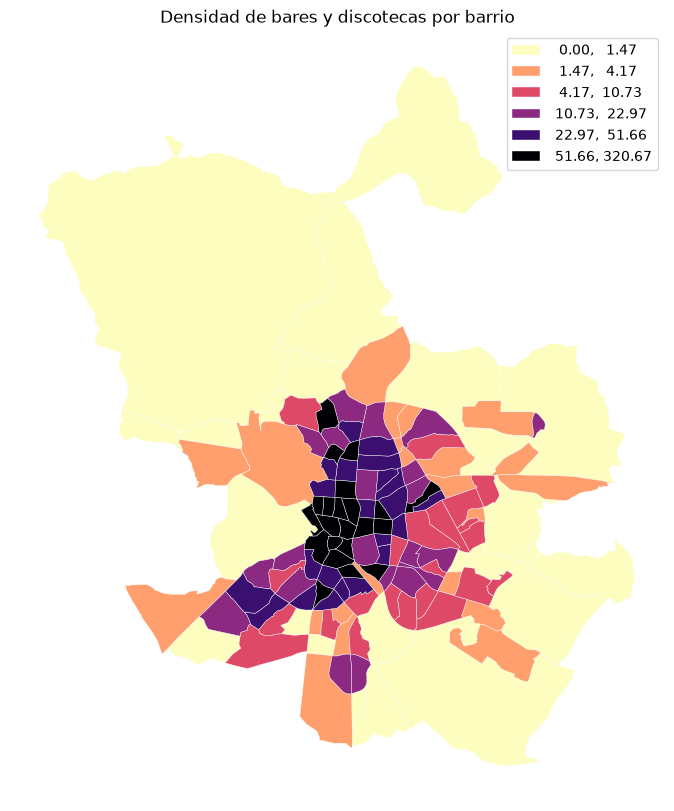

In [14]:
import matplotlib.pyplot as plt

barrios_vars["dens_noche"] = barrios_vars["dens_bares_cafeterias"] + 3 * barrios_vars["dens_discotecas"]

fig, ax = plt.subplots(figsize=(10, 10))
barrios_vars.plot(column="dens_noche", cmap="magma_r", scheme="quantiles", k=6,
                  legend=True, ax=ax, edgecolor="white", linewidth=0.3)
ax.set_axis_off()
ax.set_title("Densidad de bares y discotecas por barrio")

In [22]:
barrios_vars.to_parquet(PROCESSED / "barrios_variables.parquet")